In [21]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Set seeds for scientific reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {DEVICE}")

# Grid & Vocabulary Configuration
GRID_SIZE = 8          # 8x8 Maze Grid
WALL_PROB = 0.28       # Probability of a cell being an obstacle

# Maze Input Vocab: 0=Free, 1=Wall, 2=Start, 3=Goal
MAZE_VOCAB = {"FREE": 0, "WALL": 1, "START": 2, "GOAL": 3}

# Action Output Vocab: PAD, BOS, EOS, and directional moves U, L, R, D
ACTION_VOCAB = {"PAD": 0, "BOS": 1, "EOS": 2, "U": 3, "L": 4, "R": 5, "D": 6}
IDX_TO_ACTION = {v: k for k, v in ACTION_VOCAB.items()}

# Coordinate deltas corresponding to U, L, R, D
MOVE_DELTAS = {
    "U": (-1, 0),
    "L": (0, -1),
    "R": (0, 1),
    "D": (1, 0)
}



Running on device: cuda


In [22]:
def generate_solvable_maze(size=GRID_SIZE, wall_prob=WALL_PROB, min_path_len=4):
    """
    Generates a random 2D grid maze and uses Breadth-First Search (BFS)
    to guarantee a valid shortest path of (U, L, R, D) actions exists.
    """
    while True:
        # 1. Initialize random walls and free spaces
        grid = np.random.choice(
            [MAZE_VOCAB["FREE"], MAZE_VOCAB["WALL"]],
            size=(size, size),
            p=[1 - wall_prob, wall_prob]
        )

        # 2. Pick distinct random coordinates for Start and Goal
        start = (random.randint(0, size - 1), random.randint(0, size - 1))
        goal = (random.randint(0, size - 1), random.randint(0, size - 1))
        if start == goal:
            continue

        grid[start] = MAZE_VOCAB["START"]
        grid[goal] = MAZE_VOCAB["GOAL"]

        # 3. Breadth-First Search (BFS) for shortest action sequence
        queue = deque([(start[0], start[1], [])])
        visited = {start}

        while queue:
            r, c, path = queue.popleft()
            if (r, c) == goal:
                if len(path) >= min_path_len:
                    return grid, path, start, goal
                break

            # Explore neighbors in canonical order: U, L, R, D
            for action, (dr, dc) in MOVE_DELTAS.items():
                nr, nc = r + dr, c + dc
                if 0 <= nr < size and 0 <= nc < size:
                    if grid[nr, nc] != MAZE_VOCAB["WALL"] and (nr, nc) not in visited:
                        visited.add((nr, nc))
                        queue.append((nr, nc, path + [action]))


class MazeDataset(Dataset):
    def __init__(self, num_samples=12000, size=GRID_SIZE):
        self.samples = []
        self.max_seq_len = size * size  # Upper bound on path length

        print(f"Generating {num_samples} solvable mazes via BFS...")
        for _ in range(num_samples):
            grid, path, start, goal = generate_solvable_maze(size=size)
            # Tokenize action sequence: [BOS, ...actions..., EOS]
            seq = [ACTION_VOCAB["BOS"]] + [ACTION_VOCAB[a] for a in path] + [ACTION_VOCAB["EOS"]]
            self.samples.append((grid, seq))

        self.max_len = max(len(s[1]) for s in self.samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        grid, seq = self.samples[idx]
        # Pad sequence to uniform length for batch processing
        padded_seq = seq + [ACTION_VOCAB["PAD"]] * (self.max_len - len(seq))
        return (
            torch.tensor(grid, dtype=torch.long),
            torch.tensor(padded_seq, dtype=torch.long)
        )


# Create Training & Validation Datasets
train_dataset = MazeDataset(num_samples=50000)
val_dataset = MazeDataset(num_samples=5000)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)


Generating 50000 solvable mazes via BFS...
Generating 5000 solvable mazes via BFS...


In [23]:
class MazeTransformerSolver(nn.Module):
    def __init__(
        self,
        grid_size=GRID_SIZE,
        d_model=128,
        nhead=8,
        num_layers=4,
        dim_feedforward=256,
        dropout=0.1,
        max_seq_len=64
    ):
        super().__init__()
        self.grid_size = grid_size
        self.d_model = d_model

        # Encoder Embeddings: Token + 2D Spatial (Row + Column)
        self.maze_token_emb = nn.Embedding(len(MAZE_VOCAB), d_model)
        self.row_emb = nn.Embedding(grid_size, d_model)
        self.col_emb = nn.Embedding(grid_size, d_model)

        # Decoder Embeddings: Action Token + 1D Step Position
        self.action_token_emb = nn.Embedding(len(ACTION_VOCAB), d_model)
        self.pos_emb = nn.Embedding(max_seq_len, d_model)

        # Core Encoder-Decoder Transformer
        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        # Output projection to action vocabulary logits
        self.fc_out = nn.Linear(d_model, len(ACTION_VOCAB))

        # Precompute 2D coordinate indices for the flattened HxW grid
        rows = torch.arange(grid_size).unsqueeze(1).repeat(1, grid_size).view(-1)
        cols = torch.arange(grid_size).unsqueeze(0).repeat(grid_size, 1).view(-1)
        self.register_buffer("grid_rows", rows)
        self.register_buffer("grid_cols", cols)

    def encode_maze(self, grid):
        """
        Maps (B, H, W) grid into (B, H*W, d_model) with 2D spatial encodings.
        """
        B = grid.size(0)
        flat_grid = grid.view(B, -1)  # (B, H*W)

        tok_e = self.maze_token_emb(flat_grid)
        row_e = self.row_emb(self.grid_rows).unsqueeze(0)  # (1, H*W, d_model)
        col_e = self.col_emb(self.grid_cols).unsqueeze(0)  # (1, H*W, d_model)

        src = tok_e + row_e + col_e
        return self.transformer.encoder(src)

    def forward(self, grid, tgt_seq):
        """
        Forward pass for training with teacher forcing.
        grid: (B, H, W)
        tgt_seq: (B, T)
        """
        B, T = tgt_seq.shape

        # 1. Encode 2D Maze
        memory = self.encode_maze(grid)

        # 2. Embed Target Action Sequence with 1D Positional Encoding
        positions = torch.arange(0, T, device=tgt_seq.device).unsqueeze(0)
        tgt = self.action_token_emb(tgt_seq) + self.pos_emb(positions)

        # 3. Causal Mask (upper triangular True = masked out) & Padding Mask
        causal_mask = torch.triu(
            torch.ones(T, T, device=tgt_seq.device, dtype=torch.bool), diagonal=1
        )
        tgt_pad_mask = (tgt_seq == ACTION_VOCAB["PAD"])

        # 4. Decode
        out = self.transformer.decoder(
            tgt=tgt,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=tgt_pad_mask
        )
        return self.fc_out(out)


In [25]:
model = MazeTransformerSolver().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=ACTION_VOCAB["PAD"])

EPOCHS = 90

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0

    for grids, seqs in train_loader:
        grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)

        # Teacher Forcing: Input is [BOS, a_1, ..., a_T], Target is [a_1, ..., a_T, EOS]
        tgt_input = seqs[:, :-1]
        tgt_labels = seqs[:, 1:]

        optimizer.zero_grad()
        logits = model(grids, tgt_input)

        loss = criterion(logits.reshape(-1, len(ACTION_VOCAB)), tgt_labels.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

    # Calculate validation token accuracy
    model.eval()
    correct_tokens, total_tokens = 0, 0
    with torch.no_grad():
        for grids, seqs in val_loader:
            grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)
            tgt_input, tgt_labels = seqs[:, :-1], seqs[:, 1:]
            logits = model(grids, tgt_input)
            preds = logits.argmax(dim=-1)
            mask = tgt_labels != ACTION_VOCAB["PAD"]
            correct_tokens += (preds[mask] == tgt_labels[mask]).sum().item()
            total_tokens += mask.sum().item()

    val_acc = (correct_tokens / total_tokens) * 100
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {total_loss/len(train_loader):.4f} | Val Token Acc: {val_acc:.2f}%")


Epoch 01/90 | Train Loss: 0.9902 | Val Token Acc: 68.92%
Epoch 02/90 | Train Loss: 0.6562 | Val Token Acc: 74.93%
Epoch 03/90 | Train Loss: 0.5958 | Val Token Acc: 77.06%
Epoch 04/90 | Train Loss: 0.5705 | Val Token Acc: 76.60%
Epoch 05/90 | Train Loss: 0.5555 | Val Token Acc: 76.91%
Epoch 06/90 | Train Loss: 0.5447 | Val Token Acc: 78.32%
Epoch 07/90 | Train Loss: 0.5353 | Val Token Acc: 78.22%
Epoch 08/90 | Train Loss: 0.5309 | Val Token Acc: 77.09%
Epoch 09/90 | Train Loss: 0.5229 | Val Token Acc: 77.34%
Epoch 10/90 | Train Loss: 0.5211 | Val Token Acc: 77.72%
Epoch 11/90 | Train Loss: 0.5179 | Val Token Acc: 77.74%
Epoch 12/90 | Train Loss: 0.5121 | Val Token Acc: 78.62%
Epoch 13/90 | Train Loss: 0.5023 | Val Token Acc: 78.70%
Epoch 14/90 | Train Loss: 0.4959 | Val Token Acc: 78.61%
Epoch 15/90 | Train Loss: 0.4880 | Val Token Acc: 78.94%
Epoch 16/90 | Train Loss: 0.4845 | Val Token Acc: 79.34%
Epoch 17/90 | Train Loss: 0.4754 | Val Token Acc: 80.58%
Epoch 18/90 | Train Loss: 0.463

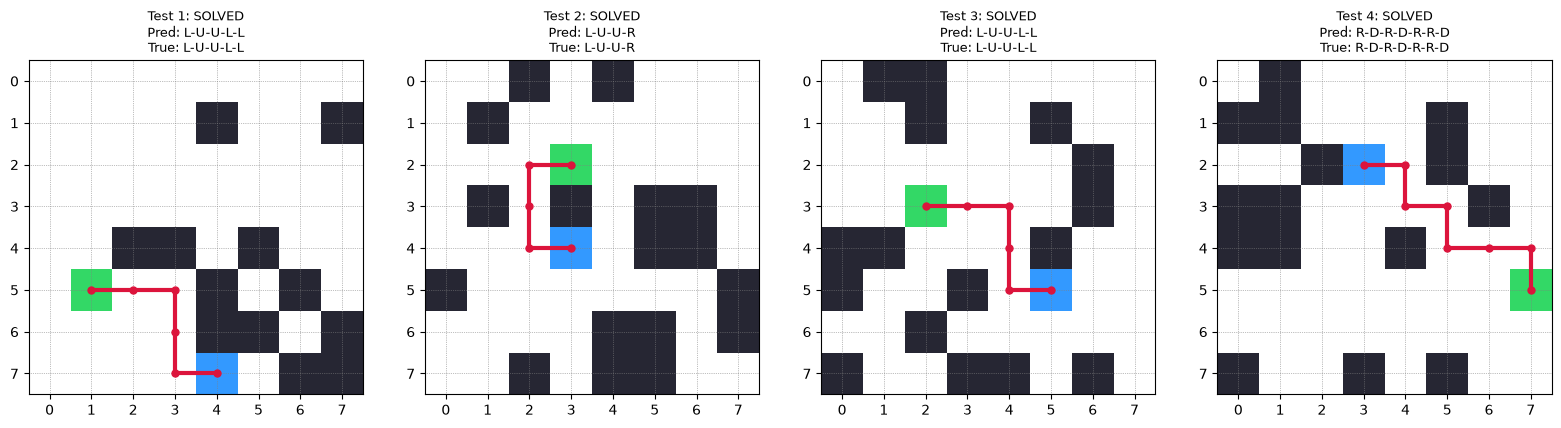

In [13]:
@torch.no_grad()
def solve_maze_autoregressive(model, grid, max_steps=40):
    """
    Takes a raw 2D maze grid and autoregressively predicts ['U', 'L', 'R', 'D']
    one token at a time until EOS is emitted.
    """
    model.eval()
    grid_tensor = torch.tensor(grid, dtype=torch.long, device=DEVICE).unsqueeze(0)
    memory = model.encode_maze(grid_tensor)

    generated = [ACTION_VOCAB["BOS"]]

    for _ in range(max_steps):
        tgt_seq = torch.tensor([generated], dtype=torch.long, device=DEVICE)
        T = tgt_seq.size(1)
        positions = torch.arange(0, T, device=DEVICE).unsqueeze(0)

        tgt = model.action_token_emb(tgt_seq) + model.pos_emb(positions)
        causal_mask = torch.triu(torch.ones(T, T, device=DEVICE, dtype=torch.bool), diagonal=1)

        out = model.transformer.decoder(tgt=tgt, memory=memory, tgt_mask=causal_mask)
        next_token_logits = model.fc_out(out[:, -1, :])
        next_token = next_token_logits.argmax(dim=-1).item()

        if next_token == ACTION_VOCAB["EOS"]:
            break
        generated.append(next_token)

    return [IDX_TO_ACTION[idx] for idx in generated[1:]]


def visualize_predictions(model, num_tests=4):
    fig, axes = plt.subplots(1, num_tests, figsize=(4 * num_tests, 4))
    if num_tests == 1:
        axes = [axes]

    for idx, ax in enumerate(axes):
        grid, true_path, start, goal = generate_solvable_maze()
        pred_actions = solve_maze_autoregressive(model, grid)

        # Trace predicted path coordinates
        curr_r, curr_c = start
        path_coords = [(curr_r, curr_c)]
        valid_trace = True

        for act in pred_actions:
            if act not in MOVE_DELTAS:
                continue
            dr, dc = MOVE_DELTAS[act]
            nr, nc = curr_r + dr, curr_c + dc
            if 0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE and grid[nr, nc] != MAZE_VOCAB["WALL"]:
                curr_r, curr_c = nr, nc
                path_coords.append((curr_r, curr_c))
            else:
                valid_trace = False
                break

        reached_goal = (curr_r, curr_c) == goal and valid_trace

        # Render grid colors
        color_map = np.ones((GRID_SIZE, GRID_SIZE, 3))
        color_map[grid == MAZE_VOCAB["WALL"]] = [0.15, 0.15, 0.2]   # Dark Slate Walls
        color_map[start] = [0.2, 0.6, 1.0]                          # Blue Start
        color_map[goal] = [0.2, 0.85, 0.4]                          # Green Goal

        ax.imshow(color_map)

        # Plot predicted trajectory line
        ys = [c for r, c in path_coords]
        xs = [r for r, c in path_coords]
        ax.plot(ys, xs, color="crimson", linewidth=3, marker="o", markersize=5, label="Pred Path")

        status = "SOLVED" if reached_goal else "FAILED"
        ax.set_title(
            f"Test {idx+1}: {status}\nPred: {'-'.join(pred_actions)}\nTrue: {'-'.join(true_path)}",
            fontsize=9
        )
        ax.set_xticks(range(GRID_SIZE))
        ax.set_yticks(range(GRID_SIZE))
        ax.grid( color="gray", linestyle=":", linewidth=0.5)

    plt.tight_layout()
    plt.show()

# Run visual evaluation on 4 unseen mazes
visualize_predictions(model, num_tests=4)

In [ ]:
# %% [Cell 3 - Updated] 2D Spatial Looped Transformer Architecture
import math

class SinusoidalLoopEncoding(nn.Module):
    """
    Generates continuous sinusoidal embeddings for loop iteration index k.
    Allows test-time compute extrapolation (K_test > K_train).
    """
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model)
        )
        self.register_buffer("div_term", div_term)

    def forward(self, k_idx, device):
        # k_idx: integer loop step (1-indexed)
        pe = torch.zeros(1, 1, self.d_model, device=device)
        k_tensor = torch.tensor([float(k_idx)], device=device)
        pe[0, 0, 0::2] = torch.sin(k_tensor * self.div_term)
        pe[0, 0, 1::2] = torch.cos(k_tensor * self.div_term)
        return pe  # (1, 1, d_model)


class LoopedTransformerEncoder(nn.Module):
    """
    Weight-tied Transformer Encoder that iteratively refines the 2D maze state
    for `num_loops` steps with Input Injection (boundary condition anchoring).
    """
    def __init__(self, d_model, nhead, dim_feedforward, dropout, num_loops):
        super().__init__()
        self.num_loops = num_loops
        # Single shared Encoder block (Pre-LN for stable deep recurrence)
        self.shared_block = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True
        )
        self.loop_emb = SinusoidalLoopEncoding(d_model)
        self.input_gate = nn.Parameter(torch.ones(1))  # Learnable anchor weight alpha
        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, src, num_loops=None):
        K = num_loops if num_loops is not None else self.num_loops
        h_init = src  # H^(0): Static maze boundary conditions
        h = src

        for k in range(1, K + 1):
            # Inject initial state H^(0) + sinusoidal loop-step encoding tau(k)
            step_enc = self.loop_emb(k, src.device)
            h_in = h + (self.input_gate * h_init) + step_enc
            h = self.shared_block(h_in)

        return self.final_norm(h)


class LoopedTransformerDecoder(nn.Module):
    """
    Weight-tied Causal Transformer Decoder that iteratively refines action
    representations across `num_loops` recurrent steps.
    """
    def __init__(self, d_model, nhead, dim_feedforward, dropout, num_loops):
        super().__init__()
        self.num_loops = num_loops
        # Single shared Decoder block (Pre-LN)
        self.shared_block = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True
        )
        self.loop_emb = SinusoidalLoopEncoding(d_model)
        self.input_gate = nn.Parameter(torch.ones(1))
        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, tgt, memory, tgt_mask=None, tgt_key_padding_mask=None, num_loops=None):
        K = num_loops if num_loops is not None else self.num_loops
        h_init = tgt  # Initial embedded action prefix
        h = tgt

        for k in range(1, K + 1):
            step_enc = self.loop_emb(k, tgt.device)
            h_in = h + (self.input_gate * h_init) + step_enc
            h = self.shared_block(
                tgt=h_in,
                memory=memory,
                tgt_mask=tgt_mask,
                tgt_key_padding_mask=tgt_key_padding_mask
            )

        return self.final_norm(h)


class MazeTransformerSolver(nn.Module):
    def __init__(
        self,
        grid_size=GRID_SIZE,
        d_model=128,
        nhead=8,
        num_layers=6,        # Treated as default `num_loops` (K)
        dim_feedforward=256,
        dropout=0.1,
        max_seq_len=128
    ):
        super().__init__()
        self.grid_size = grid_size
        self.d_model = d_model
        self.num_loops = num_layers

        # Encoder Embeddings: Token + 2D Spatial (Row + Column)
        self.maze_token_emb = nn.Embedding(len(MAZE_VOCAB), d_model)
        self.row_emb = nn.Embedding(grid_size, d_model)
        self.col_emb = nn.Embedding(grid_size, d_model)

        # Decoder Embeddings: Action Token + 1D Step Position
        self.action_token_emb = nn.Embedding(len(ACTION_VOCAB), d_model)
        self.pos_emb = nn.Embedding(max_seq_len, d_model)

        # Looped Encoder-Decoder Container (compatible with self.transformer.encoder / .decoder)
        self.transformer = nn.ModuleDict({
            "encoder": LoopedTransformerEncoder(
                d_model, nhead, dim_feedforward, dropout, num_loops=self.num_loops
            ),
            "decoder": LoopedTransformerDecoder(
                d_model, nhead, dim_feedforward, dropout, num_loops=self.num_loops
            )
        })

        # Output projection to action vocabulary logits
        self.fc_out = nn.Linear(d_model, len(ACTION_VOCAB))

        # Precompute 2D coordinate indices for the flattened HxW grid
        rows = torch.arange(grid_size).unsqueeze(1).repeat(1, grid_size).view(-1)
        cols = torch.arange(grid_size).unsqueeze(0).repeat(grid_size, 1).view(-1)
        self.register_buffer("grid_rows", rows)
        self.register_buffer("grid_cols", cols)

    def encode_maze(self, grid, num_loops=None):
        """
        Maps (B, H, W) grid into (B, H*W, d_model) via K recurrent encoder loops.
        """
        B = grid.size(0)
        flat_grid = grid.view(B, -1)  # (B, H*W)

        tok_e = self.maze_token_emb(flat_grid)
        row_e = self.row_emb(self.grid_rows).unsqueeze(0)  # (1, H*W, d_model)
        col_e = self.col_emb(self.grid_cols).unsqueeze(0)  # (1, H*W, d_model)

        src = tok_e + row_e + col_e
        return self.transformer["encoder"](src, num_loops=num_loops)

    def forward(self, grid, tgt_seq, num_loops=None):
        """
        Forward pass for training with teacher forcing.
        grid: (B, H, W)
        tgt_seq: (B, T)
        num_loops: Optional override for recurrent depth K
        """
        B, T = tgt_seq.shape

        # 1. Encode 2D Maze via Looped Encoder
        memory = self.encode_maze(grid, num_loops=num_loops)

        # 2. Embed Target Action Sequence with 1D Positional Encoding
        positions = torch.arange(0, T, device=tgt_seq.device).unsqueeze(0)
        tgt = self.action_token_emb(tgt_seq) + self.pos_emb(positions)

        # 3. Causal Mask (upper triangular True = masked out) & Padding Mask
        causal_mask = torch.triu(
            torch.ones(T, T, device=tgt_seq.device, dtype=torch.bool), diagonal=1
        )
        tgt_pad_mask = (tgt_seq == ACTION_VOCAB["PAD"])

        # 4. Decode via Looped Decoder
        out = self.transformer["decoder"](
            tgt=tgt,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=tgt_pad_mask,
            num_loops=num_loops
        )
        return self.fc_out(out)

In [18]:
model = MazeTransformerSolver().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=ACTION_VOCAB["PAD"])

EPOCHS = 30 

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0

    for grids, seqs in train_loader:
        grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)

        # Teacher Forcing: Input is [BOS, a_1, ..., a_T], Target is [a_1, ..., a_T, EOS]
        tgt_input = seqs[:, :-1]
        tgt_labels = seqs[:, 1:]

        optimizer.zero_grad()
        logits = model(grids, tgt_input)

        loss = criterion(logits.reshape(-1, len(ACTION_VOCAB)), tgt_labels.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

    # Calculate validation token accuracy
    model.eval()
    correct_tokens, total_tokens = 0, 0
    with torch.no_grad():
        for grids, seqs in val_loader:
            grids, seqs = grids.to(DEVICE), seqs.to(DEVICE)
            tgt_input, tgt_labels = seqs[:, :-1], seqs[:, 1:]
            logits = model(grids, tgt_input)
            preds = logits.argmax(dim=-1)
            mask = tgt_labels != ACTION_VOCAB["PAD"]
            correct_tokens += (preds[mask] == tgt_labels[mask]).sum().item()
            total_tokens += mask.sum().item()

    val_acc = (correct_tokens / total_tokens) * 100
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {total_loss/len(train_loader):.4f} | Val Token Acc: {val_acc:.2f}%")


Epoch 01/30 | Train Loss: 0.8324 | Val Token Acc: 76.29%
Epoch 02/30 | Train Loss: 0.5576 | Val Token Acc: 77.54%
Epoch 03/30 | Train Loss: 0.5200 | Val Token Acc: 78.30%
Epoch 04/30 | Train Loss: 0.5040 | Val Token Acc: 77.44%
Epoch 05/30 | Train Loss: 0.4851 | Val Token Acc: 80.30%
Epoch 06/30 | Train Loss: 0.4376 | Val Token Acc: 83.45%
Epoch 07/30 | Train Loss: 0.3749 | Val Token Acc: 87.02%
Epoch 08/30 | Train Loss: 0.3109 | Val Token Acc: 90.55%
Epoch 09/30 | Train Loss: 0.2352 | Val Token Acc: 93.64%
Epoch 10/30 | Train Loss: 0.1825 | Val Token Acc: 95.69%
Epoch 11/30 | Train Loss: 0.1481 | Val Token Acc: 96.54%
Epoch 12/30 | Train Loss: 0.1262 | Val Token Acc: 96.84%
Epoch 13/30 | Train Loss: 0.1112 | Val Token Acc: 97.25%
Epoch 14/30 | Train Loss: 0.0969 | Val Token Acc: 96.77%
Epoch 15/30 | Train Loss: 0.0880 | Val Token Acc: 98.03%
Epoch 16/30 | Train Loss: 0.0826 | Val Token Acc: 98.17%
Epoch 17/30 | Train Loss: 0.0746 | Val Token Acc: 98.48%
Epoch 18/30 | Train Loss: 0.067

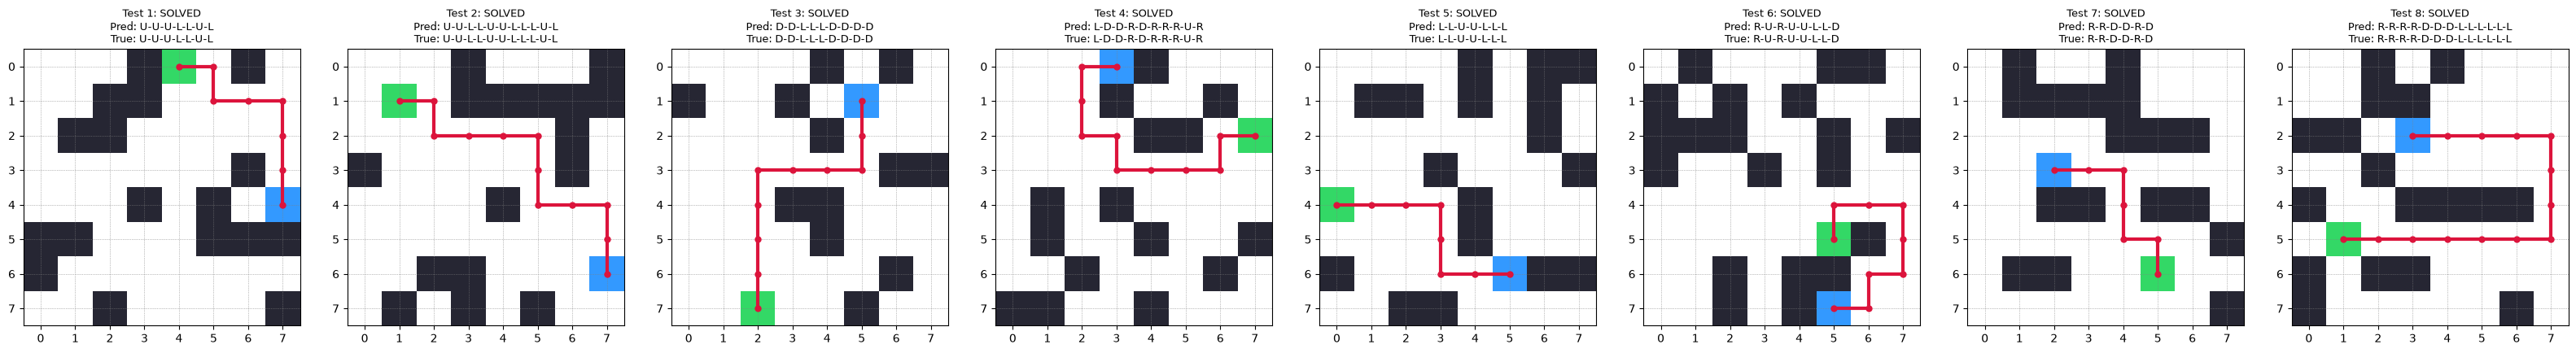

In [20]:
@torch.no_grad()
def solve_maze_autoregressive(model, grid, max_steps=40):
    """
    Takes a raw 2D maze grid and autoregressively predicts ['U', 'L', 'R', 'D']
    one token at a time until EOS is emitted.
    """
    model.eval()
    grid_tensor = torch.tensor(grid, dtype=torch.long, device=DEVICE).unsqueeze(0)
    memory = model.encode_maze(grid_tensor)

    generated = [ACTION_VOCAB["BOS"]]

    for _ in range(max_steps):
        tgt_seq = torch.tensor([generated], dtype=torch.long, device=DEVICE)
        T = tgt_seq.size(1)
        positions = torch.arange(0, T, device=DEVICE).unsqueeze(0)

        tgt = model.action_token_emb(tgt_seq) + model.pos_emb(positions)
        causal_mask = torch.triu(torch.ones(T, T, device=DEVICE, dtype=torch.bool), diagonal=1)

        out = model.transformer.decoder(tgt=tgt, memory=memory, tgt_mask=causal_mask)
        next_token_logits = model.fc_out(out[:, -1, :])
        next_token = next_token_logits.argmax(dim=-1).item()

        if next_token == ACTION_VOCAB["EOS"]:
            break
        generated.append(next_token)

    return [IDX_TO_ACTION[idx] for idx in generated[1:]]


def visualize_predictions(model, num_tests=4):
    fig, axes = plt.subplots(1, num_tests, figsize=(4 * num_tests, 4))
    if num_tests == 1:
        axes = [axes]

    for idx, ax in enumerate(axes):
        grid, true_path, start, goal = generate_solvable_maze()
        pred_actions = solve_maze_autoregressive(model, grid)

        # Trace predicted path coordinates
        curr_r, curr_c = start
        path_coords = [(curr_r, curr_c)]
        valid_trace = True

        for act in pred_actions:
            if act not in MOVE_DELTAS:
                continue
            dr, dc = MOVE_DELTAS[act]
            nr, nc = curr_r + dr, curr_c + dc
            if 0 <= nr < GRID_SIZE and 0 <= nc < GRID_SIZE and grid[nr, nc] != MAZE_VOCAB["WALL"]:
                curr_r, curr_c = nr, nc
                path_coords.append((curr_r, curr_c))
            else:
                valid_trace = False
                break

        reached_goal = (curr_r, curr_c) == goal and valid_trace

        # Render grid colors
        color_map = np.ones((GRID_SIZE, GRID_SIZE, 3))
        color_map[grid == MAZE_VOCAB["WALL"]] = [0.15, 0.15, 0.2]   # Dark Slate Walls
        color_map[start] = [0.2, 0.6, 1.0]                          # Blue Start
        color_map[goal] = [0.2, 0.85, 0.4]                          # Green Goal

        ax.imshow(color_map)

        # Plot predicted trajectory line
        ys = [c for r, c in path_coords]
        xs = [r for r, c in path_coords]
        ax.plot(ys, xs, color="crimson", linewidth=3, marker="o", markersize=5, label="Pred Path")

        status = "SOLVED" if reached_goal else "FAILED"
        ax.set_title(
            f"Test {idx+1}: {status}\nPred: {'-'.join(pred_actions)}\nTrue: {'-'.join(true_path)}",
            fontsize=9
        )
        ax.set_xticks(range(GRID_SIZE))
        ax.set_yticks(range(GRID_SIZE))
        ax.grid( color="gray", linestyle=":", linewidth=0.5)

    plt.tight_layout()
    plt.show()

# Run visual evaluation on 4 unseen mazes
visualize_predictions(model, num_tests=8)